<h1 align="center">Rwanda Maize–Urea Trial</h1>
<h2 align="center">6. Yield Prediction & Yield Drivers</h2>

Two related questions:

**Objective 3: can we predict yield for a field we have never seen, before planting?**
Only information available at planting is used (location, landscape, field observations, treatment, season). Models are scored with **grouped 5-fold cross-validation**: all plots from a field are in the same fold, so every prediction is for an unseen field. Without grouping, plots from the same field would leak into training and inflate the score.

**Objective 2a: what drives yield?**
A wider set of variables, including in-season ones such as germination and planting date, ranked by **permutation importance on held-out fields**: how much prediction error grows when a variable is shuffled.

Code: [`src/maize/prediction.py`](../src/maize/prediction.py).

> **Data note.** The trial data is confidential and is not in this repository. The outputs shown were produced on the real data. If you run this notebook without it, it uses the synthetic sample in `01_Data/sample/` and the numbers may differ.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "02_Notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from maize import config, data, plotting, prediction

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
MODE = config.data_mode()
OUT = config.output_paths(MODE)
print("Data source:", "confidential trial data (01_Data/raw)" if MODE == "raw" else "synthetic sample (01_Data/sample)")

Data source: synthetic sample (01_Data/sample)


In [2]:
_, combined = data.build_combined(MODE)
print("Pre-planting features:", prediction.PREPLANT_CATEGORICAL + prediction.PREPLANT_NUMERIC)

Pre-planting features: ['urea_rate_timing', 'season', 'meg_env', 'landscape_pos', 'slope_pos', 'soil_color', 'rockness', 'lat', 'long', 'alt_clean', 'soil_depth', 'slope', 'cult_land']


## 1. Model comparison

In [3]:
metrics, preds = prediction.cross_validate(combined)
metrics_x, _ = prediction.cross_validate(combined, drop_implausible=True)
pd.concat([metrics, metrics_x], ignore_index=True)

,model,MAE,RMSE,R2,n_plots,outlier_excluded
0,Ridge regression,1.252,1.994,0.032,1590,False
1,Random forest,1.269,2.015,0.011,1590,False
2,Mean baseline,1.286,2.032,-0.005,1590,False
3,Random forest,1.201,1.520,0.094,1589,True
4,Ridge regression,1.211,1.537,0.073,1589,True
5,Mean baseline,1.253,1.601,-0.005,1589,True


* The **random forest** is the best model, but only narrowly ahead of ridge regression. It cuts MAE by about 16% compared with predicting the average yield.
* It explains about **21%** of yield variation on unseen fields. The single 50.1 t/ha plot drags this down: without it, R² rises to about 0.32.
* An honest reading: the model is **useful for setting expectations or ranking sites, not for forecasting one farm's harvest**.

## 2. Where does it go wrong?

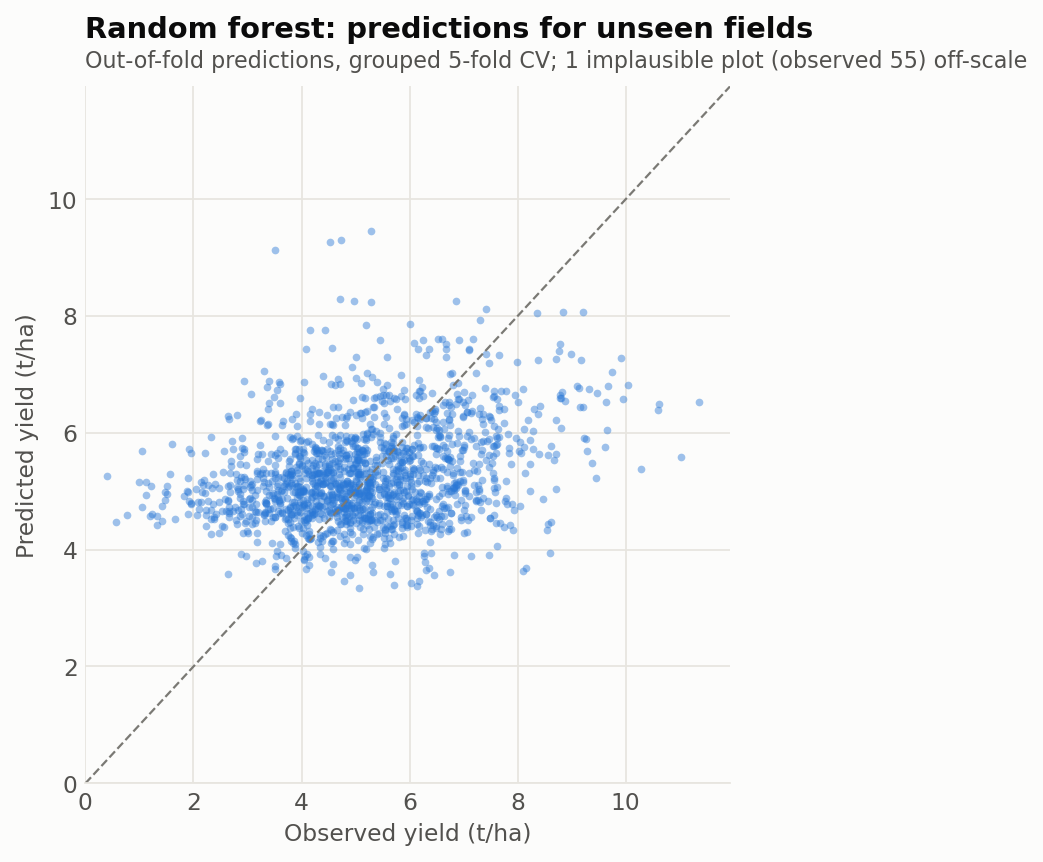

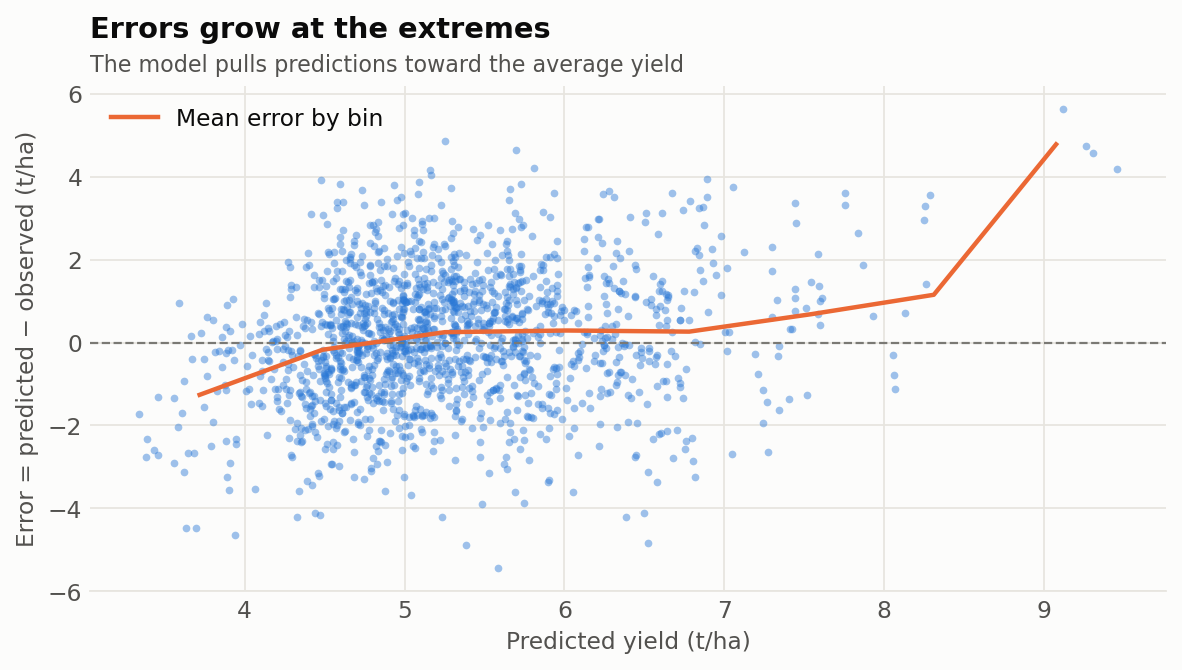

In [4]:
plotting.observed_vs_predicted(preds, OUT.figures / "rf_observed_vs_predicted.png")
plotting.prediction_errors(preds, OUT.figures / "rf_prediction_errors.png")
display(Image(OUT.figures / "rf_observed_vs_predicted.png", width=520))
display(Image(OUT.figures / "rf_prediction_errors.png", width=640))

In [5]:
prediction.error_by_group(preds)

,meg_env,n,MAE,mean_error
0,Highlands,566,1.244,0.063
1,Low-Mid-Dry,453,1.255,0.047
2,Low-Mid-Wet,307,1.214,0.150
3,Transitional,256,1.427,0.012
4,NaN,8,0.904,0.060


Errors are similar in every mega-environment (MAE 1.2–1.3 t/ha). The model **shrinks extremes toward the average**: it under-predicts the best fields and over-predicts the worst. This is typical when the variables that separate very good from very poor fields, such as rainfall, soil fertility and management quality, are missing. The enrichment in earlier analysis targets exactly this.

## 3. What drives yield? (Objective 2a)

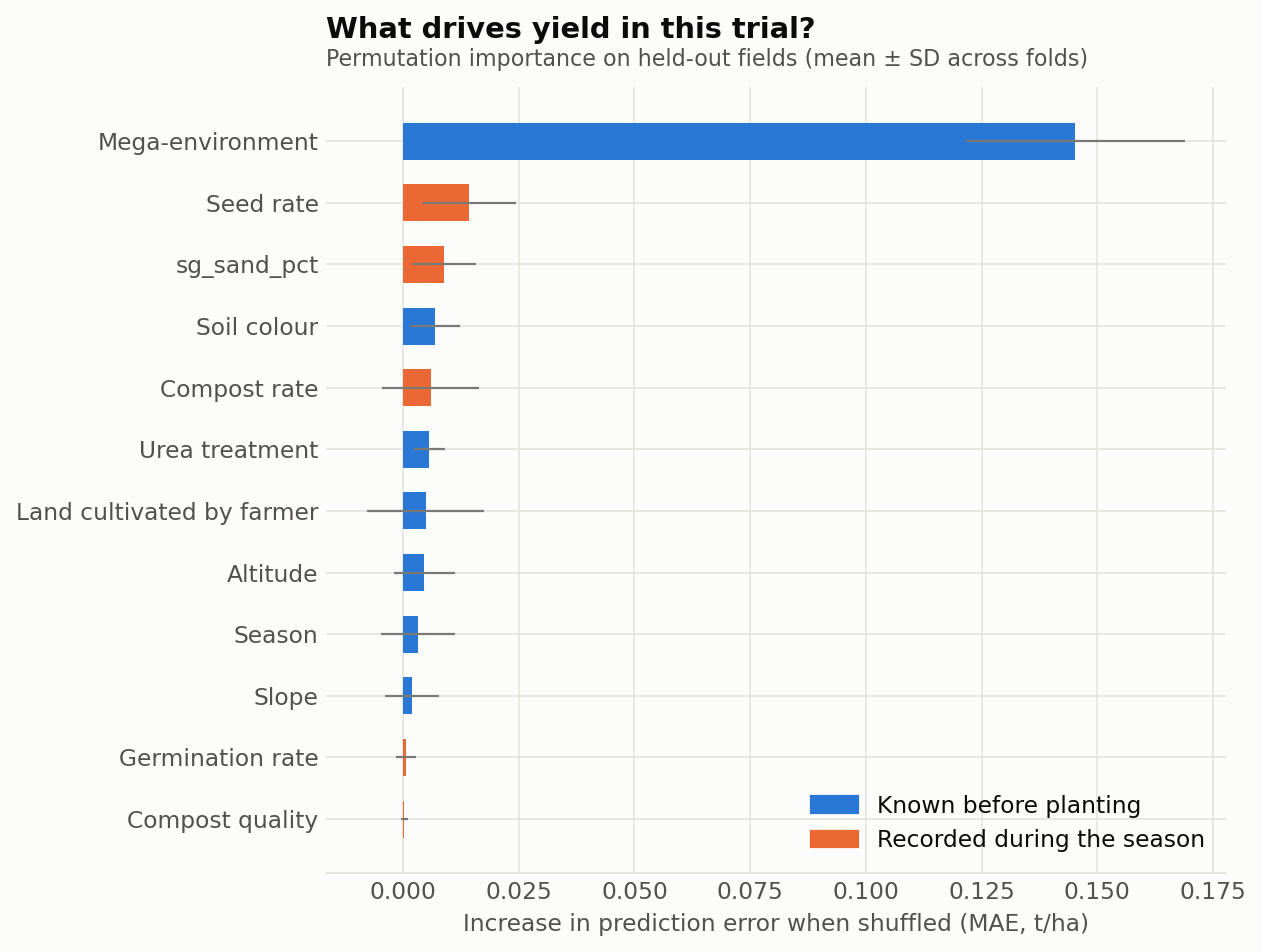

,label,importance_mae,fold_sd,known_before_planting,share_missing
0,Mega-environment,1.452e-01,2.370e-02,True,0.005
1,Seed rate,1.422e-02,1.010e-02,False,0.000
2,sg_sand_pct,8.811e-03,6.953e-03,False,0.065
3,Soil colour,6.872e-03,5.344e-03,True,0.005
4,Compost rate,5.963e-03,1.048e-02,False,0.000
5,Urea treatment,5.673e-03,3.313e-03,True,0.000
6,Land cultivated by farmer,4.890e-03,1.266e-02,True,0.033
7,Altitude,4.610e-03,6.628e-03,True,0.013
8,Season,3.149e-03,8.009e-03,True,0.000
9,Slope,1.955e-03,5.875e-03,True,0.005


In [6]:
imp = prediction.driver_importance(combined)
plotting.driver_importance(imp, OUT.figures / "driver_importance.png")
display(Image(OUT.figures / "driver_importance.png", width=700))
imp[["label", "importance_mae", "fold_sd", "known_before_planting", "share_missing"]].head(12)

Slope stands out. A simple breakdown shows the size of the effect:

In [7]:
ok = combined[~combined["flag_implausible_yield"]]
(ok.groupby(pd.cut(ok["slope"], [-1, 3, 8, 15, 40], labels=["0-3%", "4-8%", "9-15%", ">15%"]), observed=True)["yield_tha"]
   .agg(plots="size", mean_yield="mean"))

,plots,mean_yield
slope,,
0-3%,356,5.118
4-8%,363,5.103
9-15%,538,5.247
>15%,324,5.251


**Drivers, in plain terms**
1. **Slope.** Flat fields yield about 2 t/ha more than steep ones. Steep fields lose topsoil and nutrients, and they tend to sit at higher altitude (r ≈ 0.4).
2. **Site and timing:** mega-environment, altitude, planting date and germination rate.
3. **Seed rate** ranks highly but mostly separates sites (it barely varies within a field), so it should not be read as a causal effect.
4. **Urea treatment ranks low for *predicting* yield**, even though its effect is real (notebook 04). A ~0.5 t/ha treatment gain is small next to the ~2 t/ha gap between good and poor fields.

Permutation importance measures predictive association, not cause, and correlated variables (slope and altitude, for example) share credit.

**Next:** notebook 07 turns the results into advice.